## THỰC NGHIỆM C - ẢNH HƯỞNG CỦA SỐ TẦNG ẨN

### 1. Mục tiêu
Khảo sát ảnh hưởng của độ sâu mạng MLP đến sai số xấp xỉ hàm Gaussian hai chiều, khả năng hội tụ và thời gian huấn luyện. Số tầng ẩn khảo sát từ 1 đến 4.

### 2. Chỉ số và đầu ra
Ghi Validation MSE/RMSE/MAE, Test MSE/RMSE/MAE, thời gian huấn luyện, best epoch, train/validation loss theo epoch và checkpoint cho từng seed.

### 3. Import thư viện, baseline và kiểm tra dữ liệu

In [1]:
from pathlib import Path
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import config as cfg
from dataset import get_all_loaders
from model import MLPRegressor
from train import train_model
from evaluate import evaluate_model

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
for folder in (RESULTS_DIR, FIGURES_DIR, CHECKPOINT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64
EPOCHS = 200
LEARNING_RATE = 0.01
SEEDS = list(getattr(cfg, "TRAIN_SEEDS", [0, 1, 2]))
DEVICE = cfg.get_device()

if not (PROJECT_DIR / "data.py").exists():
    raise FileNotFoundError("Không tìm thấy data.py.")

import shutil
cfg.DATA_DIR.mkdir(parents=True, exist_ok=True)
for split in ("train", "val", "test"):
    target = cfg.DATA_DIR / f"{split}.csv"
    source = PROJECT_DIR / f"{split}.csv"
    if not target.exists() and source.exists():
        shutil.copy2(source, target)
    if not target.exists():
        raise FileNotFoundError(
            f"Thiếu {target}. Hãy đặt {split}.csv vào thư mục data/ "
        )

print(f"Device: {DEVICE} | Seeds: {SEEDS}")
print(f"Train/Validation/Test: {cfg.DATA_DIR}")

Đã tạo thành công file model.py!
Đã tạo thành công file train.py!
Đã tạo thành công file evaluate.py!
Device: cpu | Seeds: [0, 1, 2]
Train/Validation/Test: D:\Hocsau_thuchanh\BTL01\CODETV4\data


### 4. Hàm hỗ trợ đánh giá validation và tổng hợp kết quả

In [2]:
def evaluate_loader_mse_mae(model, loader, device):
    """Đánh giá trên loader được chỉ định; không cập nhật trọng số."""
    model.eval()
    predictions, targets = [], []
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            pred = model(x_batch).detach().cpu().numpy().reshape(-1)
            predictions.append(pred)
            targets.append(y_batch.detach().cpu().numpy().reshape(-1))
    y_pred = np.concatenate(predictions)
    y_true = np.concatenate(targets)
    mse = float(np.mean((y_true - y_pred) ** 2))
    mae = float(np.mean(np.abs(y_true - y_pred)))
    return mse, float(np.sqrt(mse)), mae


def summarize_runs(df_runs, group_col):
    """Tổng hợp mean/std cho các metric; không lấy trung bình cột Seed."""
    metric_cols = [
        "Val_MSE", "Val_RMSE", "Val_MAE",
        "Test_MSE", "Test_RMSE", "Test_MAE",
        "Train_Time_Sec", "Best_Epoch"
    ]
    grouped = df_runs.groupby(group_col)[metric_cols].agg(["mean", "std"])
    grouped.columns = [f"{metric}_{stat.upper()}" for metric, stat in grouped.columns]
    return grouped.reset_index()


def save_loss_history(records, filename):
    df = pd.DataFrame(records)
    df.to_csv(RESULTS_DIR / filename, index=False)
    return df


def plot_mean_loss(df_loss, group_col, group_values, title, output_path, ncols=2):
    """Vẽ mean train/validation loss theo epoch, trung bình trên các seed."""
    mean_loss = (
        df_loss.groupby([group_col, "Epoch"], as_index=False)[["Train_Loss", "Val_Loss"]]
        .mean()
    )
    nrows = int(np.ceil(len(group_values) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 4*nrows), squeeze=False)
    for value, ax in zip(group_values, axes.ravel()):
        part = mean_loss[mean_loss[group_col] == value]
        ax.plot(part["Epoch"], part["Train_Loss"], label="Train loss")
        ax.plot(part["Epoch"], part["Val_Loss"], label="Validation loss")
        ax.set_title(f"{group_col} = {value}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MSE loss")
        ax.grid(True, alpha=0.3)
        ax.legend()
    for ax in axes.ravel()[len(group_values):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### 5. Cố định độ rộng và khai báo các cấu hình độ sâu

In [3]:
FIXED_NEURONS = 10
LAYER_VALUES = [1, 2, 3, 4]
print(f"Thực nghiệm C: {FIXED_NEURONS} nơ-ron/tầng; số tầng ẩn = {LAYER_VALUES}")

Thực nghiệm C: 10 nơ-ron/tầng; số tầng ẩn = [1, 2, 3, 4]


### 6. Chạy thực nghiệm C
Mỗi cấu hình (số tầng, seed) được huấn luyện độc lập. Best epoch dựa trên validation loss; test chỉ được đánh giá sau huấn luyện.

In [4]:
FIXED_NEURONS = 10
LAYER_VALUES = [1, 2, 3, 4]

def run_experiment_C():
    run_records, loss_records = [], []

    for n_layers in LAYER_VALUES:
        for seed in SEEDS:
            cfg.set_seed(seed)
            train_loader, val_loader, test_loader = get_all_loaders(
                batch_size=BATCH_SIZE, seed=seed
            )
            model = MLPRegressor(
                input_dim=2, hidden_dim=FIXED_NEURONS,
                num_layers=n_layers, output_dim=1
            )

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()
            model, train_losses, val_losses = train_model(
                train_loader, val_loader, model,
                epochs=EPOCHS, lr=LEARNING_RATE, device=DEVICE
            )
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start

            best_epoch_idx = int(np.argmin(val_losses))
            best_epoch = best_epoch_idx + 1
            val_mse, val_rmse, val_mae = evaluate_loader_mse_mae(
                model, val_loader, DEVICE
            )

            # Test chỉ dùng đánh giá sau huấn luyện.
            test_metrics, _ = evaluate_model(model, test_loader, device=DEVICE)

            checkpoint_path = CHECKPOINT_DIR / f"model_C_layers{n_layers}_neurons{FIXED_NEURONS}_seed{seed}.pt"
            torch.save({
                "model_state_dict": model.state_dict(),
                "experiment": "C",
                "num_layers": n_layers,
                "hidden_dim": FIXED_NEURONS,
                "seed": seed,
                "best_epoch": best_epoch,
                "best_val_loss": float(val_losses[best_epoch_idx]),
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
                "learning_rate": LEARNING_RATE,
            }, checkpoint_path)

            run_records.append({
                "Num_Layers": n_layers, "Hidden_Neurons_Per_Layer": FIXED_NEURONS,
                "Seed": seed, "Best_Epoch": best_epoch,
                "Train_Loss_At_Best_Epoch": float(train_losses[best_epoch_idx]),
                "Val_Loss_At_Best_Epoch": float(val_losses[best_epoch_idx]),
                "Val_MSE": val_mse, "Val_RMSE": val_rmse, "Val_MAE": val_mae,
                "Test_MSE": float(test_metrics["MSE"]),
                "Test_RMSE": float(test_metrics["RMSE"]),
                "Test_MAE": float(test_metrics["MAE"]),
                "Train_Time_Sec": elapsed,
                "Checkpoint": str(checkpoint_path.relative_to(PROJECT_DIR)),
            })
            for epoch, (tr_loss, va_loss) in enumerate(zip(train_losses, val_losses), start=1):
                loss_records.append({
                    "Num_Layers": n_layers, "Hidden_Neurons_Per_Layer": FIXED_NEURONS,
                    "Seed": seed, "Epoch": epoch,
                    "Train_Loss": float(tr_loss), "Val_Loss": float(va_loss)
                })
            print(f"C | layers={n_layers} | seed={seed} | "
                  f"val_mse={val_mse:.8g} | test_mse={test_metrics['MSE']:.8g} | "
                  f"time={elapsed:.2f}s")

    df_runs = pd.DataFrame(run_records)
    df_summary = summarize_runs(df_runs, "Num_Layers")
    df_loss = pd.DataFrame(loss_records)
    df_runs.to_csv(RESULTS_DIR / "results_C_raw.csv", index=False)
    df_summary.to_csv(RESULTS_DIR / "results_C.csv", index=False)
    df_loss.to_csv(RESULTS_DIR / "loss_history_C.csv", index=False)
    return df_runs, df_summary, df_loss


df_runs_C, df_summary_C, df_losses_C = run_experiment_C()
display(df_summary_C.round(8))

C | layers=1 | seed=0 | val_mse=0.00012342603 | test_mse=9.0569287e-05 | time=33.90s
C | layers=1 | seed=1 | val_mse=0.00019143042 | test_mse=9.3542803e-05 | time=27.16s
C | layers=1 | seed=2 | val_mse=0.00035735808 | test_mse=0.00032469974 | time=28.03s
C | layers=2 | seed=0 | val_mse=2.0149162e-05 | test_mse=2.0311656e-05 | time=36.87s
C | layers=2 | seed=1 | val_mse=2.2305801e-05 | test_mse=1.9841864e-05 | time=33.90s
C | layers=2 | seed=2 | val_mse=3.1400665e-05 | test_mse=2.3034283e-05 | time=36.28s
C | layers=3 | seed=0 | val_mse=6.108879e-06 | test_mse=5.0788913e-06 | time=39.85s
C | layers=3 | seed=1 | val_mse=1.9956478e-05 | test_mse=1.3818403e-05 | time=39.14s
C | layers=3 | seed=2 | val_mse=5.1884608e-06 | test_mse=3.6549793e-06 | time=38.03s
C | layers=4 | seed=0 | val_mse=3.4375337e-06 | test_mse=3.3775216e-06 | time=42.56s
C | layers=4 | seed=1 | val_mse=2.3595723e-05 | test_mse=1.9616433e-05 | time=36.33s
C | layers=4 | seed=2 | val_mse=4.2873739e-06 | test_mse=3.2324854

,Num_Layers,Val_MSE_MEAN,Val_MSE_STD,Val_RMSE_MEAN,Val_RMSE_STD,Val_MAE_MEAN,Val_MAE_STD,Test_MSE_MEAN,Test_MSE_STD,Test_RMSE_MEAN,Test_RMSE_STD,Test_MAE_MEAN,Test_MAE_STD,Train_Time_Sec_MEAN,Train_Time_Sec_STD,Best_Epoch_MEAN,Best_Epoch_STD
0,1,0.000224,0.000120,0.014616,0.003955,0.011477,0.003646,0.000170,0.000134,0.012403,0.004865,0.009559,0.004369,29.696674,3.667720,144.000000,32.908965
1,2,0.000025,0.000006,0.004938,0.000588,0.003733,0.000661,0.000021,0.000002,0.004587,0.000186,0.003458,0.000314,35.681381,1.572116,181.333333,20.231988
2,3,0.000010,0.000008,0.003072,0.001212,0.002138,0.001015,0.000008,0.000005,0.002628,0.000959,0.001915,0.000933,39.007303,0.916438,176.000000,8.717798
3,4,0.000010,0.000011,0.002927,0.001675,0.002189,0.001252,0.000009,0.000009,0.002688,0.001508,0.002016,0.001225,37.840306,4.171496,174.666667,31.214313


### 7. Trực quan hóa sai số và thời gian huấn luyện

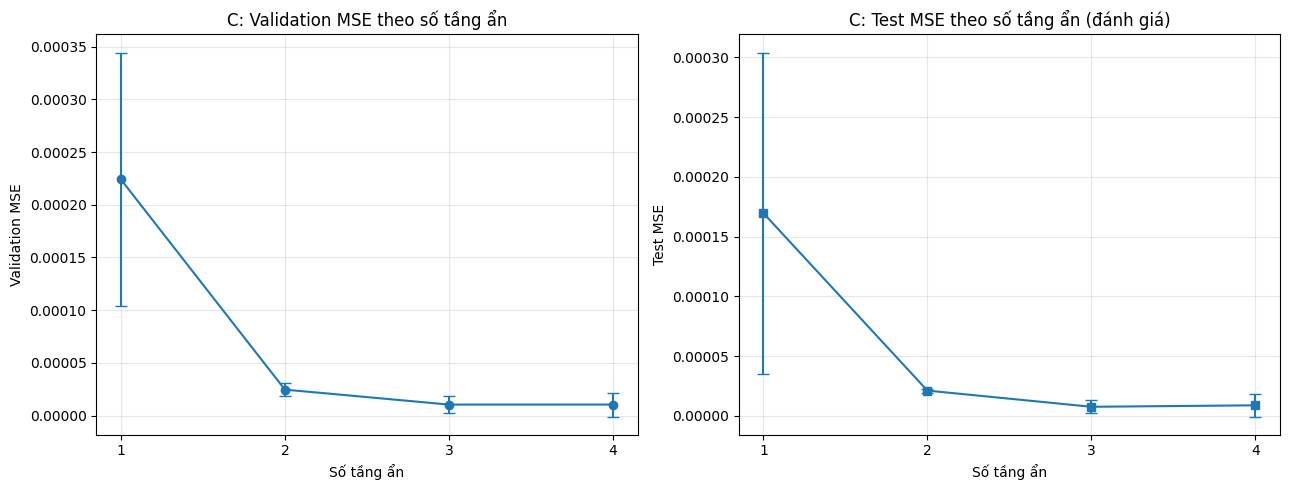

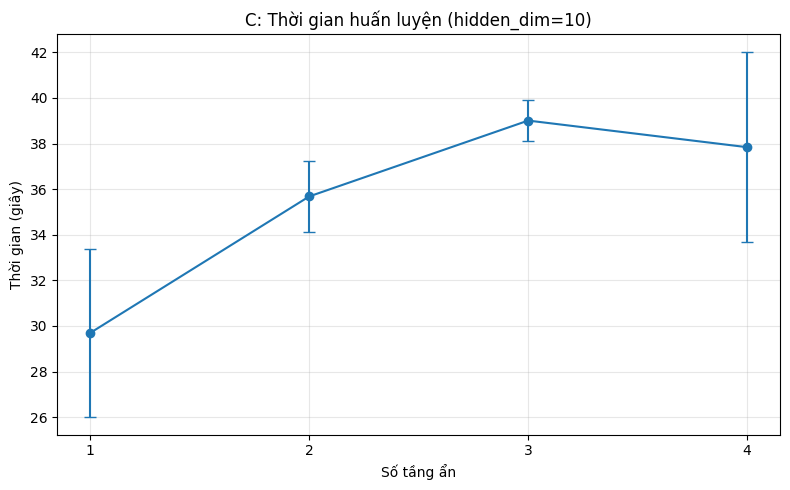

In [5]:
x = df_summary_C["Num_Layers"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].errorbar(x, df_summary_C["Val_MSE_MEAN"], yerr=df_summary_C["Val_MSE_STD"], marker="o", capsize=4)
axes[0].set(title="C: Validation MSE theo số tầng ẩn", xlabel="Số tầng ẩn", ylabel="Validation MSE")
axes[0].set_xticks(LAYER_VALUES); axes[0].grid(True, alpha=0.3)
axes[1].errorbar(x, df_summary_C["Test_MSE_MEAN"], yerr=df_summary_C["Test_MSE_STD"], marker="s", capsize=4)
axes[1].set(title="C: Test MSE theo số tầng ẩn (đánh giá)", xlabel="Số tầng ẩn", ylabel="Test MSE")
axes[1].set_xticks(LAYER_VALUES); axes[1].grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "plot_C_errors.png", dpi=180, bbox_inches="tight")
plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(x, df_summary_C["Train_Time_Sec_MEAN"], yerr=df_summary_C["Train_Time_Sec_STD"], marker="o", capsize=4)
ax.set(title=f"C: Thời gian huấn luyện (hidden_dim={FIXED_NEURONS})", xlabel="Số tầng ẩn", ylabel="Thời gian (giây)")
ax.set_xticks(LAYER_VALUES); ax.grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "plot_C_training_time.png", dpi=180, bbox_inches="tight")
plt.show(); plt.close(fig)

### 8. Đường cong hội tụ theo số tầng ẩn
Dùng train/validation loss theo epoch để so sánh tốc độ hội tụ và dấu hiệu quá khớp.

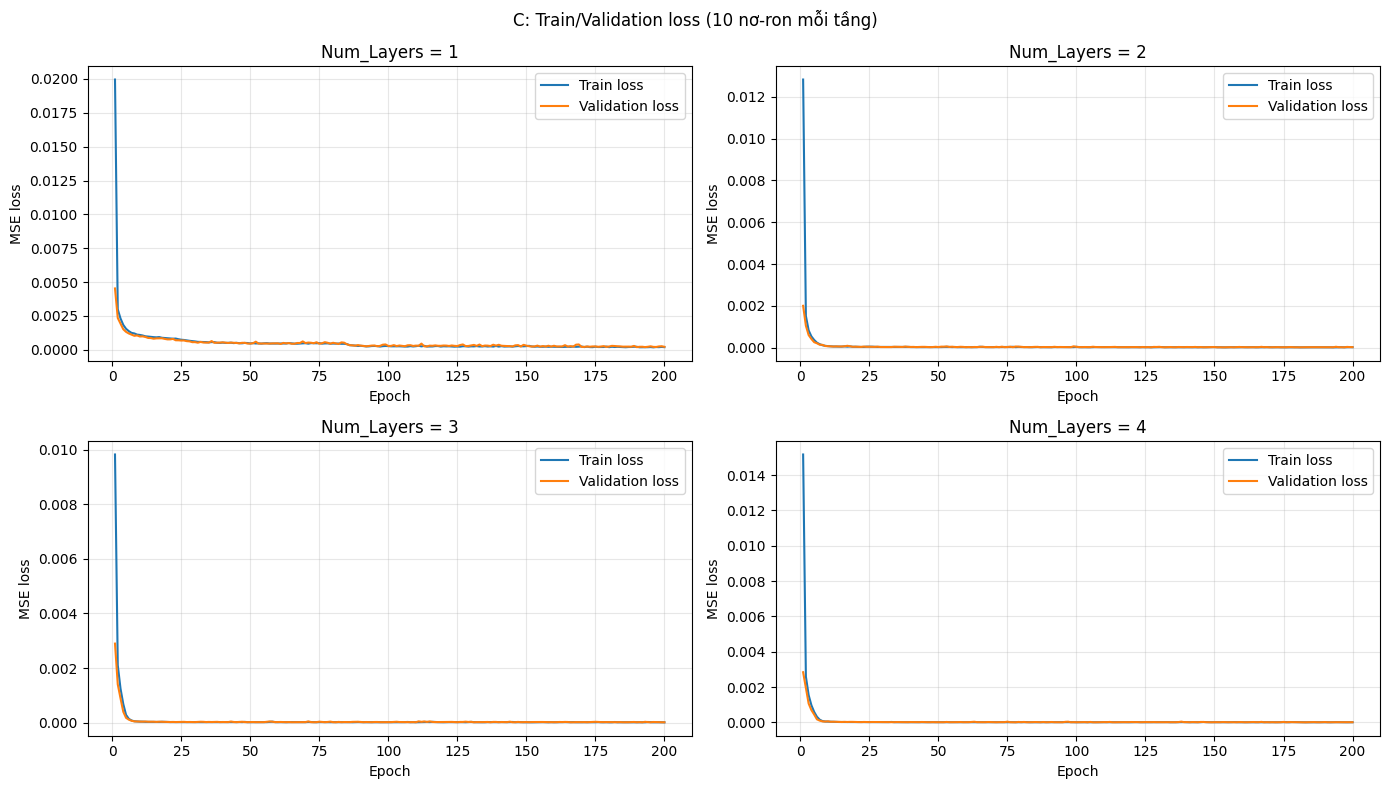

In [6]:
plot_mean_loss(df_losses_C, "Num_Layers", LAYER_VALUES,
               f"C: Train/Validation loss ({FIXED_NEURONS} nơ-ron mỗi tầng)",
               FIGURES_DIR / "plot_C_loss_curves.png", ncols=2)